# Stage 6 (part 1) — Hyper-parameter tuning of the classical models

| Part | Prompt | Code |
|---|---|---|
| 1 | 6.1 Tuning framework (Optuna: seeded TPE, median pruning over the 5 folds, SQLite studies, leakage tests) | `src/tuning.py`, `tests/test_tuning.py` |
| 2 | 6.2 Tune the 10 classical families (+ CatBoost Tweedie and hurdle CatBoost for regression), 5-seed re-runs, default vs tuned | `src/tuning.py` (`BUDGET`, `run_all`) |

Same Feature Set B, the same 5 expanding folds, the same inner slice for thresholds/early stopping, the same metrics and references as
Stage 4 (rule 7). Objectives (Decision 4.19): classification **maximise BSS**, regression **minimise MAE**. The test years (targets
2020–2025) are not touched. Part 2 of this stage (6.3 deep-model tuning, 6.4 ablations) follows after review.

### Step 1 — Setup

**WHAT:** imports, paths, seeds, versions (Optuna is new in this stage).

**WHY:** reproducibility; Optuna's samplers and defaults change between versions (e.g. TPE's default number of random start-up trials).

**Look for:** Optuna 5.0.0 and the four CPU threads.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, optuna

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, models as Mo, splits as S, tuning as T, reporting as Rep

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0)
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
import os, sklearn, xgboost, lightgbm, catboost, torch
print("optuna", optuna.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| lightgbm", lightgbm.__version__, "| catboost", catboost.__version__, "| torch", torch.__version__, "| CPUs", os.cpu_count())

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


optuna 5.0.0 | sklearn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | torch 2.14.1+cu130 | CPUs 4


**Interpretation:** Optuna 5.0.0 with the same library versions as Stages 4–5; 4 CPU cores, no GPU.

**Decision:** Optuna 5.0.0 added to `requirements.txt`. Its API was checked in the installed version (rule 13): `TPESampler(seed=…)`
(default 10 random start-up trials), `MedianPruner(n_startup_trials, n_warmup_steps)`, SQLite storage via a `sqlite:///` URL,
`get_param_importances` with `FanovaImportanceEvaluator(seed=…)`.

**Paper note:** *Hyper-parameters were optimised with Optuna 5.0.0 (TPE sampler, median pruning) on CPU.*

# Part 1 — Prompt 6.1: the tuning framework

### Step 2 — How Optuna searches, and why it must never see the test years

**Hyper-parameters vs parameters.** A model *learns* its parameters (coefficients, tree splits, network weights) from the training
rows. Hyper-parameters (regularisation strength, tree depth, learning rate, …) are chosen *before* fitting. Tuning = choosing them by
how well the fitted model forecasts days it has not seen — here, the 5 validation blocks of our expanding folds.

**TPE (Tree-structured Parzen Estimator), `TPESampler(seed=42)`.**
1. The first 10 trials are drawn at random from the search space (Optuna's default `n_startup_trials=10`), to see the landscape.
2. After that, the finished trials are split into a "good" group (the best ≈ 10–25 %) and a "bad" group.
3. TPE fits one density to the parameter values of the good trials, l(x), and one to the bad trials, g(x) (kernel density
   estimates — "Parzen estimators"; one per hyper-parameter in the default, independent mode).
4. It draws 24 candidates from l(x) and runs the one with the largest ratio l(x)/g(x): values that were common among good trials
   and rare among bad ones. This ratio is proportional to the expected improvement, so TPE balances exploring and exploiting.
5. Repeat. The seed fixes the random draws, so the same study can be reproduced trial by trial.

*Alternatives considered:* grid search (cost grows exponentially with the number of hyper-parameters and wastes trials on
unimportant ones), random search (a strong baseline, but does not learn from earlier trials), Gaussian-process Bayesian
optimisation (good for few continuous parameters, awkward with categorical/conditional ones such as SGD's `eta0`, which only exists
for some schedules).

**Median pruning across folds, `MedianPruner(n_startup_trials=5, n_warmup_steps=1)`.** A trial is evaluated fold by fold (fold 1
first, the smallest and cheapest). After each fold it reports the running mean of the objective. From the 6th trial on and from fold 2
on, if this running mean is worse than the **median of the earlier trials' running means at the same fold**, the trial is stopped
("pruned"). Because every trial sees the folds in the same order, the comparison is fair (all trials are judged on the same years).
A trial that is already worse than half of its predecessors after two folds rarely becomes the best one, so pruning spends the
compute on promising regions. Risk: a setting that is weak on early (drier) years but strong after 2016 can be pruned too early —
we accept this, and we check below how many trials were pruned.

**Why tuning on the test set would invalidate results.** Every trial is a question "how good is this setting?". If the answer comes
from 2020–2025, after 50 questions the selected setting is the one that fits *those* years best — including their noise. Its test
score is then a maximum over 50 noisy scores and is biased upwards (the "winner's curse"); it no longer estimates how the model will
do on *new* years. The test set must be used once, at the end, for a model that was chosen without it. Note that the same bias
applies, more mildly, to our CV scores of tuned models: they were selected on the same validation blocks they are reported on. The
locked test set is what will give the unbiased estimate (rule 4).

**Protocol inside one trial (identical to Stage 4):** for each fold → inner split of the training fold (last 3 target years = slice)
→ fit on inner-train, predict slice → CSI threshold (classification) and early-stopping number of trees/epochs (boosters, MLP) →
refit on the whole training fold → forecast the validation block → score. Preprocessing (one-hot month + scaling) lives inside each
Pipeline, so it is fitted on training rows only. The validation labels are read only when the fold's score is computed. Model seed 0.

### Step 3 — What the tuner sees

**WHAT:** load the data exactly as `tuning.prepare` does, and list the folds, the last target date and the objectives.

**WHY:** a direct check that the 2020–2025 rows are dropped *before* any trial starts (not just that the folds avoid them).

**Look for:** last target date 2019-12-31; five validation blocks 2005–07 … 2017–19; objectives BSS (max) / MAE (min).

In [2]:
d = T.prepare("cls")
print("rows:", len(d["X"]), "| features:", d["X"].shape[1], "| last target date:", S.target_dates(d["X"].index).max().date())
print("objectives:", T.OBJECTIVE, "| model seed in trials:", T.TUNE_SEED, "| sampler seed:", T.SAMPLER_SEED)
pd.DataFrame([{"fold": k + 1, "train targets": f"{S.target_dates(tr).min().date()} .. {S.target_dates(tr).max().date()}",
               "n_train": len(tr), "validation targets": f"{S.target_dates(va).min().date()} .. {S.target_dates(va).max().date()}",
               "n_val": len(va)} for k, (tr, va) in enumerate(d["folds"])])

rows: 14214 | features: 115 | last target date: 2019-12-31
objectives: {'cls': ('BSS', 'maximize'), 'reg': ('MAE', 'minimize')} | model seed in trials: 0 | sampler seed: 42


,fold,train targets,n_train,validation targets,n_val
0,1,1981-01-31 .. 2004-12-30,8735,2005-01-01 .. 2007-12-31,1095
1,2,1981-01-31 .. 2007-12-30,9830,2008-01-01 .. 2010-12-31,1096
2,3,1981-01-31 .. 2010-12-30,10926,2011-01-01 .. 2013-12-31,1096
3,4,1981-01-31 .. 2013-12-30,12022,2014-01-01 .. 2016-12-31,1096
4,5,1981-01-31 .. 2016-12-30,13118,2017-01-01 .. 2019-12-31,1095


**Interpretation:** the tuner works on 14,214 development rows whose last target is 2019-12-31; the 2020–2025 rows are removed in
`prepare()` before folds, references or trials exist. The five validation blocks (3 years each, 1,095–1,096 days) and the expanding
training sets (8,735 → 13,118 rows) are exactly those of Stage 4.

**Decision:** tuning uses the Stage-4 folds unchanged (rule 7).

**Paper note:** *Hyper-parameters were selected exclusively on five expanding-window validation blocks (2005–2019); the 2020–2025
period played no part in tuning.*

### Step 4 — Automated proof: no test-year access, no validation-label leakage

**WHAT:** run `tests/test_tuning.py` (11 tests):
1. *prepared data end in 2019* (both tasks) and each fold trains strictly before its validation block;
2. *poisoning test*: every 2020–2025 row (features and labels) is replaced by garbage, a 3-trial study is re-run, and the trial
   scores and sampled parameters must be identical (both tasks);
3. *negative control*: a deliberately leaky fold (2020+ rows added to fold 5's training set) must change the score — proves the
   poisoning test can detect a leak;
4. *validation-label test*: for folds 1 and 5, every label from the validation block onwards is scrambled; forecasts, the CSI
   threshold and the early-stopping tree count must not change (SGD, Ridge, LightGBM);
5. *spy test*: every fit and the threshold choice see only rows of the training fold, and the threshold slice is out-of-sample for
   the inner fit;
6. the study uses a seeded TPE sampler and a median pruner and reports all 5 folds; 7. `tuning.py` never calls the test getter.

**WHY:** "the code is designed not to leak" is a claim; a test that fails when leakage is introduced is evidence (rule 5).

**Alternatives considered:** reading the code only (not reproducible evidence); checking timestamps of fitted rows only (would miss
leakage through thresholds or early stopping).

**Look for:** all tests pass.

In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "-p", "no:cacheprovider", "tests/test_tuning.py", "-v"],
                   cwd=ROOT, capture_output=True, text=True)
print("\n".join(l.split("tests/test_tuning.py::")[-1] for l in r.stdout.splitlines() if "::" in l or " passed" in l or " failed" in l))

test_prepared_data_end_before_the_test_years[cls] PASSED [  9%]
test_prepared_data_end_before_the_test_years[reg] PASSED [ 18%]
test_poisoning_the_test_years_changes_nothing[cls] PASSED [ 27%]
test_poisoning_the_test_years_changes_nothing[reg] PASSED [ 36%]
test_negative_control_a_leaky_fold_is_detected PASSED [ 45%]
test_validation_labels_do_not_change_forecasts_thresholds_or_trees[cls-sgd_logloss-params0] PASSED [ 54%]
test_validation_labels_do_not_change_forecasts_thresholds_or_trees[reg-ridge-params1] PASSED [ 63%]
test_validation_labels_do_not_change_forecasts_thresholds_or_trees[cls-lightgbm-params2] PASSED [ 72%]
test_fits_and_threshold_only_see_training_rows_of_the_fold PASSED [ 81%]
test_study_uses_seeded_tpe_median_pruner_and_reports_every_fold PASSED [ 90%]
test_tuning_code_never_unlocks_the_test_getter PASSED [100%]
============================= 11 passed in 29.04s ==============================


**Interpretation:** all 11 tests pass. In particular: replacing every 2020–2025 value by garbage leaves every trial score and every
sampled parameter set bit-identical, while the negative control (the same garbage leaked into fold 5's training rows) changes the score —
so the test is able to detect the leak it guards against. Scrambling all labels from a validation block onwards leaves forecasts,
the CSI threshold and the LightGBM early-stopping tree count unchanged: validation labels enter only the final score.

**Decision:** the framework is accepted for Stage 6.2; the tests run with the rest of the suite (`python -m pytest tests/`).

**Paper note:** *Automated tests confirmed that neither the held-out test years nor validation labels could influence model fitting,
thresholds or early stopping during tuning.*

# Part 2 — Prompt 6.2: tuning the classical models

### Step 5 — Run (or load) all 20 studies and the 5-seed re-runs

**WHAT:** for each (model, task) in `T.BUDGET`: `T.tune` (resumes the SQLite study in `models/optuna/` until it has the budgeted
number of finished trials), then `T.rerun_best` (best parameters, seeds 0–4 — seed 0 only for the deterministic lbfgs/coordinate
descent models, Decision 4.4 — through the normal runners), then `T.merge_results` copies the scores into `cv_results.csv` as
`<model>_tuned`. The studies were computed with `python src/tuning.py --workers 4` (4 studies in parallel, one thread each);
this cell only loads them, and would recompute them identically if `models/optuna/` were empty.

**Budgets** (playbook: ≈ 50–100 trials for fast models, fewer for slow ones):
SGD 100; Ridge/Lasso 50, ElasticNet 60 (closed form / coordinate descent, seconds per trial); XGBoost and LightGBM 50; CatBoost,
CatBoost Tweedie 40; hurdle CatBoost 30; RF 25; MLP 30; logistic L2 (lbfgs) 30, L1 (saga) 20, elastic net (saga) 25 — the saga
solver needs up to ≈ 5 CPU-minutes per trial for weakly regularised settings, and a 1–2-dimensional convex problem needs few trials.
Hurdle: only the wet-day amount model (CatBoost, log target + smearing) is tuned; inside the trials P(wet) is the *default*
Stage-4 CatBoost classifier (fixed, so this study need not wait for the classifier study), and the 5-seed re-run combines the
**tuned** classifier with the tuned amount model.
CatBoost Tweedie also tunes the variance power (1.1–1.9). Tree caps: 3,000 with early stopping (patience 100) on the slice.

**WHY:** one budget table makes the effort per model explicit; unequal effort is a known source of unfair comparisons.

**Look for:** completed/pruned/failed trials per study and the runtime.

In [4]:
for task, name in T.BUDGET:
    T.tune(name, task, T.BUDGET[task, name])
    T.rerun_best(name, task)
print("part files merged:", T.merge_results())
studies = {(task, name): T.load_study(name, task) for task, name in T.BUDGET}

rows = []
for (task, name), st in studies.items():
    b = T.load_best(name, task)
    states = pd.Series([t.state.name for t in st.trials]).value_counts()
    minutes = sum(t.duration.total_seconds() for t in st.trials if t.state.name in ("COMPLETE", "PRUNED")) / 60
    rows.append({"task": task, "model": name, "budget": T.BUDGET[task, name], "complete": states.get("COMPLETE", 0),
                 "pruned": states.get("PRUNED", 0), "failed": states.get("FAIL", 0),
                 "threads": T.RF_THREADS if name == "random_forest" else T.THREADS,
                 "trial_minutes": round(minutes, 1), "best_trial": b["best_trial"],
                 "objective": b["objective"], "best_value_seed0": round(b["best_value"], 4)})
budget = pd.DataFrame(rows)
budget.to_csv(TAB / "06_tuning_budget.csv", index=False)
print("sum of trial times over all studies: %.0f min (single-thread except RF)" % budget.trial_minutes.sum())
budget

part files merged: 20


sum of trial times over all studies: 716 min (single-thread except RF)


,task,model,budget,complete,pruned,failed,threads,trial_minutes,best_trial,objective,best_value_seed0
0,cls,logreg_l2,30,15,15,0,1,10.7,24,BSS,0.254
1,cls,logreg_l1,20,12,8,1,1,36.2,13,BSS,0.253
2,cls,logreg_enet,25,14,11,0,1,25.5,14,BSS,0.254
3,cls,sgd_logloss,100,48,52,0,1,3.1,85,BSS,0.253
4,cls,random_forest,15,10,5,1,4,88.5,11,BSS,0.246
5,cls,xgboost,50,22,28,0,1,15.4,29,BSS,0.266
6,cls,lightgbm,50,35,15,1,1,52.2,12,BSS,0.267
7,cls,catboost,40,16,24,0,1,113.1,25,BSS,0.268
8,cls,mlp,30,19,11,0,1,40.6,11,BSS,0.252
9,reg,ridge,50,22,28,0,1,0.6,31,MAE,7.361


**Interpretation:**
- **Budgets and pruning:** 15–64 % of the trials of each study were pruned (SGD 52–64 %, boosters 30–65 %). "Failed" trials (3 in total)
  are trials that were running when the batch was stopped and restarted (see below); they were not counted towards the budget.
- **Compute:** 716 trial-minutes in total (single thread, RF 4 threads); wall-clock ≈ 5.1 h on 4 cores (13:11–18:18 UTC) including two
  restarts — far above the 45–60 min hoped for. The cost is dominated by CatBoost (113 / 87 min, ≈ 3 min per full 5-fold trial on one
  thread) and Random Forest (88 / 132 min).
- **Two changes during the run (disclosed, DECISIONS 6.4–6.5):** (1) RF trials with `max_features` ≈ 1 and 700–800 trees took 30–60 min each
  on one thread, so the RF budget was cut from 25 to **15** trials and RF was re-run with 4 threads after the other studies (results are
  identical to 1e-14 mm); (2) Lasso/ElasticNet with α < 0.01 stalled for > 40 min per trial at the 20,000-iteration cap, unconverged; they
  now use the precomputed Gram matrix (`precompute=True`, same objective, ≤ 2 s per trial, converged with `max_iter=200000`), and both
  studies were restarted from scratch. Restarted studies resume from SQLite, so their trial sequence is not bit-for-bit what one
  uninterrupted run with seed 42 would give; the SQLite files are the record.
- **Best trial numbers:** the MLP regression optimum is trial 0 and CatBoost Tweedie trial 4 — both inside the 10 random start-up trials, i.e.
  TPE found nothing better afterwards (see Step 11).

**Decision:** budgets as in the table (RF 15, saga-logistic 20–25, MLP 30, CatBoost 40, XGBoost/LightGBM 50, linear regression 50–60,
SGD 100). Saved as `reports/tables/06_tuning_budget.csv`.

**Paper note:** *Trial budgets ranged from 15 (random forest) to 100 (SGD) trials per model and task, with median pruning terminating
15–64 % of trials early; the total tuning cost was about 12 CPU-hours.*

### Step 6 — How much did pruning save?

**WHAT:** for one booster and one linear study, plot every trial's running mean after each fold (pruned trials in red), and count
the fold evaluations that pruning skipped across all studies.

**WHY:** to see the pruner at work and to check it is not too aggressive (e.g. pruning almost everything).

**Look for:** red lines that stop after fold 2–4 below/above the median, and the share of fold fits saved.

fold evaluations skipped by pruning: 1324 of 4395 (30%)


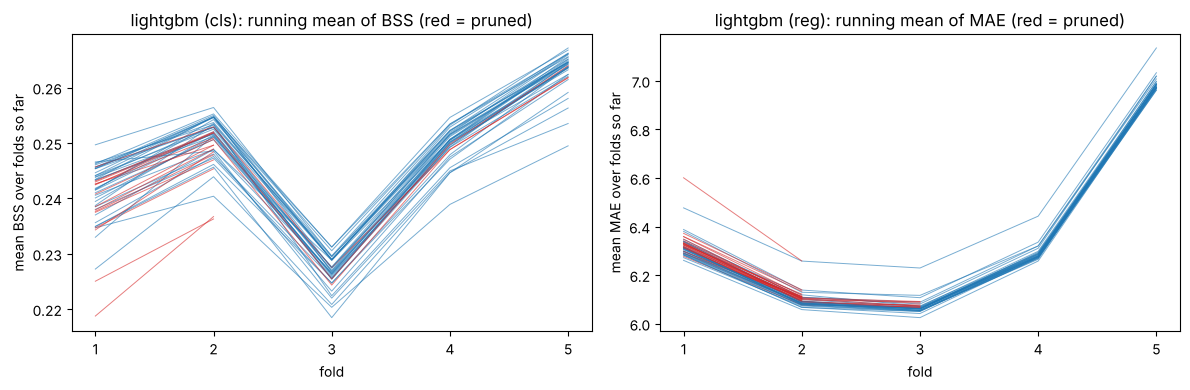

In [5]:
def folds_done(t):
    return len(t.intermediate_values)
saved = sum(5 - folds_done(t) for st in studies.values() for t in st.trials if t.state.name == "PRUNED")
total = sum(5 for st in studies.values() for t in st.trials)
print(f"fold evaluations skipped by pruning: {saved} of {total} ({saved / total:.0%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key in zip(axes, [("cls", "lightgbm"), ("reg", "lightgbm")]):
    for t in studies[key].trials:
        iv = t.intermediate_values
        if iv:
            ax.plot([s + 1 for s in iv], list(iv.values()), color="tab:red" if t.state.name == "PRUNED" else "tab:blue",
                    lw=0.7, alpha=0.6)
    ax.set(title=f"{key[1]} ({key[0]}): running mean of {T.OBJECTIVE[key[0]][0]} (red = pruned)", xlabel="fold",
           ylabel=f"mean {T.OBJECTIVE[key[0]][0]} over folds so far", xticks=range(1, 6))
fig.tight_layout(); save(fig, "06_pruning_intermediate_values.png"); plt.show()

**Interpretation:** pruning skipped 1,324 of 4,395 fold evaluations (30 %). The plot shows why the comparison must be made *at the same
fold*: every trial's running mean dips at fold 3 (BSS) and jumps at fold 5 (MAE), because fold difficulty varies far more than the settings
do. Pruned trials (red) are those below the pack after folds 1–2. A few red lines reach fold 5: the median pruner also checks after the last
fold, so those trials were labelled "pruned" without saving compute. That is harmless, because a trial worse than the median at fold 5
cannot be the best one, but in Part 2 the check will be skipped at the last fold.

**Decision:** keep `MedianPruner(n_startup_trials=5, n_warmup_steps=1)`.

**Paper note:** *Median pruning on the running fold-mean of the objective reduced the number of fold evaluations by 30 %.*

### Step 7 — Best parameters, and are any at the edge of the search range?

**WHAT:** the best (seed-0) parameters of every study, and a flag when a numeric value lies within 2 % of either end of its range
(measured on the log scale for log-scaled parameters).

**WHY:** a best value at the boundary means the optimum may lie outside the range — the range, not the model, limited the result.

**Look for:** boundary flags, especially for regularisation strength.

In [6]:
rows = []
for (task, name), st in studies.items():
    bt = st.best_trial
    for p, dist in bt.distributions.items():
        v = bt.params[p]
        flag = ""
        if hasattr(dist, "low"):
            lo, hi, x = (np.log(dist.low), np.log(dist.high), np.log(v)) if dist.log else (dist.low, dist.high, v)
            pos = (x - lo) / (hi - lo)
            flag = "LOW edge" if pos <= 0.02 else "HIGH edge" if pos >= 0.98 else ""
            rng = f"{dist.low:g} – {dist.high:g}" + (" (log)" if dist.log else "")
        else:
            rng = "{" + ", ".join(map(str, dist.choices)) + "}"
        rows.append({"task": task, "model": name, "param": p, "range": rng,
                     "best": f"{v:.3g}" if isinstance(v, float) else v, "boundary": flag})
best_params = pd.DataFrame(rows)
best_params.to_csv(TAB / "06_best_params.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(best_params)

,task,model,param,range,best,boundary
0,cls,logreg_l2,C,0.0001 – 100 (log),0.0114,
1,cls,logreg_l1,C,0.0001 – 100 (log),0.0128,
2,cls,logreg_enet,C,0.0001 – 100 (log),0.0135,
3,cls,logreg_enet,l1_ratio,0.1 – 0.9,0.153,
4,cls,sgd_logloss,alpha,1e-06 – 0.1 (log),0.000367,
5,cls,sgd_logloss,penalty,"{l2, l1, elasticnet}",elasticnet,
6,cls,sgd_logloss,learning_rate,"{optimal, invscaling, adaptive, constant}",adaptive,
7,cls,sgd_logloss,l1_ratio,0.1 – 0.9,0.884,HIGH edge
8,cls,sgd_logloss,eta0,0.0001 – 0.1 (log),0.000639,
9,cls,random_forest,n_estimators,200 – 800,750,


**Interpretation — what the best settings say:**
- **Strong shrinkage everywhere.** All three penalised logistic models choose C ≈ 0.011–0.013 (≈ 90× stronger than the L2 default C = 1), whatever
  the penalty type. The *amount* of shrinkage matters, not L1 vs L2. With 125 highly collinear columns (Decision 4.8) the data support only a
  few effective directions: persistence, humidity and season.
- **Boosters learn slowly and shallowly.** Learning rates of 0.011–0.023 (the lower end of 0.01–0.2), XGBoost depth 3–4, LightGBM 20–21 leaves,
  `min_child_weight` 5–19, column subsampling 0.57–0.73, and LightGBM `reg_lambda` 7–9. Physically: next-day rain at one grid cell depends on a
  few smooth, mostly additive signals (rain today, column moisture, seasonal cycle) with weak interactions. Deep trees and fast learning would
  fit noise. CatBoost is the exception (depth 7–8). Its oblivious (symmetric) trees use the same split for a whole level, so a depth-8 CatBoost
  tree is much more constrained than a depth-8 XGBoost tree.
- **Random forests want big leaves.** For regression the best leaf size is 35 days with depth 9. Averaging many days per leaf is the RF's
  way of shrinking towards the mean.
- **Tweedie variance power 1.33.** This is a compound Poisson–gamma distribution with relatively more weight on occurrence than on amount
  (p → 1 would be Poisson-like, p → 2 gamma-like).
- **MLP:** two layers of ≈ 90–120 units, dropout 0.2–0.3, learning rate ≈ 2e-4 (5× lower than the default), large batches. In other words,
  heavily regularised, slow training.

**Boundary flags (the range, not the model, may have limited the result):** Ridge α = 99 (upper edge of 1e-4–1e2). Ridge's α acts on the
un-normalised sum of squares, so for 13,000 rows α = 100 is still weak shrinkage. Also: CatBoost-cls depth 8 (upper edge), XGBoost-reg depth 3
(lower edge), CatBoost-reg learning rate 0.021 (lower edge 0.02), LightGBM-reg `reg_lambda` 8.7 (upper edge), ElasticNet-reg `l1_ratio`
0.89 (i.e. ≈ Lasso) and SGD-cls `l1_ratio` 0.88. All point the same way: *more* regularisation than the playbook ranges allow.

**Decision:** the playbook ranges are kept for this run (pre-specified). Extending the flagged ranges (e.g. Ridge α to 1e4, CatBoost depth
to 10, XGBoost depth 2, `reg_lambda` to 100) is proposed for the researcher's decision; it is cheap for Ridge and moderate for the boosters.
Saved as `06_best_params.csv`.

**Paper note:** *Optimal configurations were uniformly strongly regularised — low learning rates, shallow trees, large leaves and strong
coefficient shrinkage — consistent with a weak, largely additive predictive signal; several optima lay at the edge of the pre-specified
search ranges.*

### Step 8 — Reproducibility and the "winner's curse" of seed 0

**WHAT:** for each tuned model compare (a) the best trial's value (seed 0, inside Optuna), (b) the re-run with seed 0 through
`run_cv`, (c) the mean of seeds 1–4.

**WHY:** (a) = (b) proves the tuner and the runner use the same protocol (a mismatch would be a bug — rule 11). (c) < (a) would show
that tuning partly selected settings that were lucky *for seed 0*; seeds 1–4 were not used for selection, so they are an honest
check of that part of the optimism.

**Look for:** |a − b| ≈ 0 (except the hurdle, whose re-run uses the tuned instead of the default classifier — a deliberate
difference); the size of a − c relative to the default-vs-tuned gains in Step 9.

In [7]:
cv = pd.read_csv(E.RESULTS)
rows = []
for task, name in T.BUDGET:
    metric = T.OBJECTIVE[task][0]
    r = cv[(cv.model == f"{name}_tuned") & (cv.task == task) & (cv.feature_set == "B") & (cv.metric == metric)]
    per_seed = r.groupby("seed")["value"].mean()
    rows.append({"task": task, "model": name, "metric": metric, "a_best_trial": T.load_best(name, task)["best_value"],
                 "b_rerun_seed0": per_seed.get(0), "c_seeds_1_4": per_seed.drop(0).mean() if len(per_seed) > 1 else np.nan,
                 "n_seeds": len(per_seed)})
rep = pd.DataFrame(rows)
rep["a_minus_b"] = rep.a_best_trial - rep.b_rerun_seed0
sign = np.where(rep.metric == "MAE", -1, 1)
rep["seed0_optimism"] = sign * (rep.a_best_trial - rep.c_seeds_1_4)       # > 0: seed 0 better than the other seeds
rep.round(4)

,task,model,metric,a_best_trial,b_rerun_seed0,c_seeds_1_4,n_seeds,a_minus_b,seed0_optimism
0,cls,logreg_l2,BSS,0.254,0.254,NaN,1,0.000e+00,NaN
1,cls,logreg_l1,BSS,0.253,0.253,0.253,5,0.000e+00,0.000e+00
2,cls,logreg_enet,BSS,0.254,0.254,0.254,5,0.000e+00,0.000e+00
3,cls,sgd_logloss,BSS,0.253,0.253,0.253,5,0.000e+00,-2.000e-04
4,cls,random_forest,BSS,0.246,0.246,0.244,5,0.000e+00,1.600e-03
5,cls,xgboost,BSS,0.266,0.266,0.262,5,0.000e+00,3.600e-03
6,cls,lightgbm,BSS,0.267,0.267,0.264,5,0.000e+00,2.700e-03
7,cls,catboost,BSS,0.268,0.268,0.264,5,0.000e+00,3.400e-03
8,cls,mlp,BSS,0.252,0.252,0.246,5,0.000e+00,5.000e-03
9,reg,ridge,MAE,7.361,7.361,NaN,1,0.000e+00,NaN


**Interpretation:**
- **(a) = (b) exactly** (difference 0) for every model except the hurdle (5e-4 mm). The hurdle re-run deliberately uses the tuned instead of
  the default classifier. So the tuner and the runner compute the same thing, and there is no hidden difference between "tuning" and "reporting".
- **Seed-0 optimism (a − c):** for the classification boosters 0.0027–0.0036 BSS, for the MLP 0.005. This is the **same size as the tuning gains**
  in Step 9 (0.004–0.006). For regression it is negligible for the boosters and RF (≤ 0.006 mm). It is large for the MLP (0.09 mm), SGD (0.06 mm),
  hurdle (0.03 mm) and Tweedie (0.013 mm). Tuning with one seed partly selects settings that were lucky for that seed: the best of 30–50
  noisy scores is biased upwards (winner's curse). Deterministic models (lbfgs, closed form, coordinate descent) have no seed noise to exploit.

**Decision:** default-vs-tuned comparisons are reported both with all 5 seeds and with **seeds 1–4 only**. Seeds 1–4 were not used for
selection, so that comparison removes the seed part of the optimism (the fold-selection part remains; only the test set removes it).
For the deep-model tuning (6.3), consider averaging ≥ 2 seeds inside each trial for noisy models.

**Paper note:** *Re-running the selected configurations with seeds not used during tuning showed that up to half of the apparent tuning
gain of the stochastic models reflected favourable seed-specific noise.*

### Step 9 — Default vs tuned, paired across folds

**WHAT:** for each family, the Stage-4 default and the tuned model on Set B: fold-wise difference of the seed-averaged objective
(tuned − default), its mean and std over the 5 folds, the number of folds in which tuning helped, and the same for the secondary
metric (PR-AUC / MSESS).

**WHY:** folds differ far more from each other (regimes) than models do; pairing by fold removes that shared variation (Decision 4.11).
With 5 folds a sign test cannot reach p < 0.05 unless all 5 agree (p = 0.0625 two-sided), so we report win counts and effect sizes,
not p-values.

**Alternatives considered:** comparing 5-fold means only (hides the fold structure); a paired t-test on 5 differences (very low power,
normality untestable).

"Δ seeds 1-4" repeats the comparison without seed 0 (the seed used inside the trials), which removes the part of the gain that
comes from selecting a setting that was lucky for seed 0 (Step 8).

**Look for:** gains larger than the seed std, consistent across folds — and which families gained most (those with the worst
defaults, e.g. SGD and RF, should gain most).

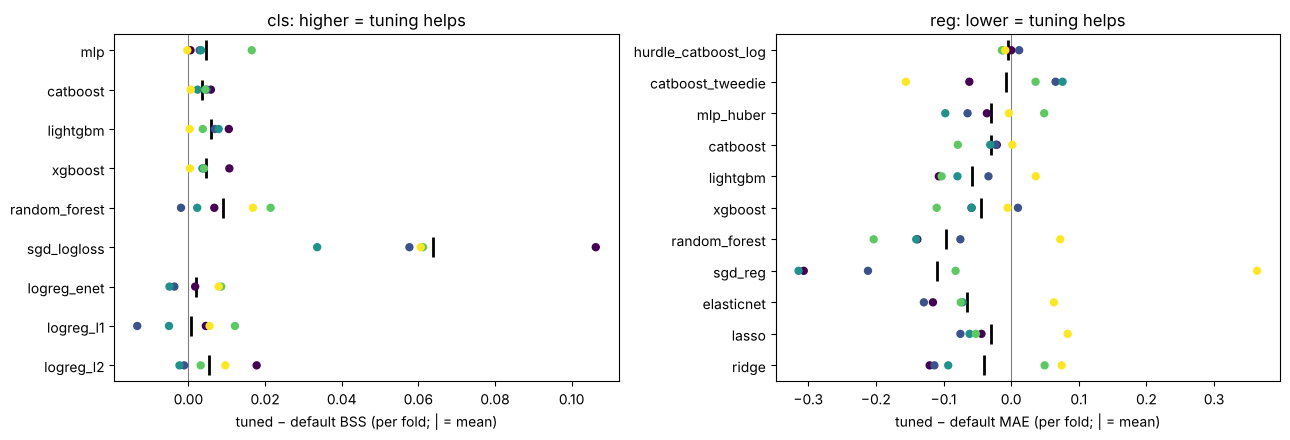

,task,model,objective,default,tuned,Δ,Δ fold std,folds improved,Δ seeds 1-4,tuned seed std,2nd metric,2nd Δ,2nd folds improved
0,cls,logreg_l2,BSS,0.249,0.254,5.400e-03,0.008,3/5,5.400e-03,NaN,PR_AUC,-1.000e-04,2/5
1,cls,logreg_l1,BSS,0.253,0.253,7.000e-04,0.010,3/5,7.000e-04,0.000e+00,PR_AUC,1.100e-03,5/5
2,cls,logreg_enet,BSS,0.252,0.254,1.900e-03,0.006,3/5,1.900e-03,0.000e+00,PR_AUC,4.000e-04,3/5
3,cls,sgd_logloss,BSS,0.189,0.253,6.390e-02,0.026,5/5,7.620e-02,1.000e-04,PR_AUC,8.800e-03,5/5
4,cls,random_forest,BSS,0.235,0.244,9.100e-03,0.010,4/5,8.900e-03,9.000e-04,PR_AUC,1.800e-03,4/5
5,cls,xgboost,BSS,0.259,0.263,4.500e-03,0.004,5/5,4.100e-03,2.100e-03,PR_AUC,6.000e-04,3/5
6,cls,lightgbm,BSS,0.259,0.265,5.900e-03,0.004,5/5,5.000e-03,1.900e-03,PR_AUC,6.000e-04,3/5
7,cls,catboost,BSS,0.261,0.265,3.600e-03,0.002,5/5,2.300e-03,2.200e-03,PR_AUC,1.000e-04,2/5
8,cls,mlp,BSS,0.243,0.247,4.600e-03,0.007,4/5,4.200e-03,2.700e-03,PR_AUC,-2.000e-04,3/5
9,reg,ridge,MAE,7.402,7.361,-4.060e-02,0.095,3/5,-4.060e-02,NaN,MSESS,-3.900e-03,1/5


In [8]:
SECOND = {"cls": "PR_AUC", "reg": "MSESS"}
def per_fold(model, task, metric, seeds=None):
    r = cv[(cv.model == model) & (cv.task == task) & (cv.feature_set == "B") & (cv.metric == metric)]
    r = r if seeds is None or r.seed.nunique() == 1 else r[r.seed.isin(seeds)]
    return r.groupby("fold")["value"].mean()

def improved(dd, m):
    return f"{int((dd < 0).sum() if m in Rep.LOWER_IS_BETTER else (dd > 0).sum())}/5"

rows, diffs = [], {}
for task, name in T.BUDGET:
    m1, m2 = T.OBJECTIVE[task][0], SECOND[task]
    d1 = per_fold(f"{name}_tuned", task, m1) - per_fold(name, task, m1)
    d1_clean = per_fold(f"{name}_tuned", task, m1, seeds=[1, 2, 3, 4]) - per_fold(name, task, m1, seeds=[1, 2, 3, 4])
    d2 = per_fold(f"{name}_tuned", task, m2) - per_fold(name, task, m2)
    diffs[task, name] = d1
    rows.append({"task": task, "model": name, "objective": m1, "default": per_fold(name, task, m1).mean(),
                 "tuned": per_fold(f"{name}_tuned", task, m1).mean(), "Δ": d1.mean(), "Δ fold std": d1.std(),
                 "folds improved": improved(d1, m1), "Δ seeds 1-4": d1_clean.mean(),
                 "tuned seed std": cv[(cv.model == f"{name}_tuned") & (cv.task == task) & (cv.metric == m1)]
                 .groupby("seed")["value"].mean().std(),
                 "2nd metric": m2, "2nd Δ": d2.mean(), "2nd folds improved": improved(d2, m2)})
dvt = pd.DataFrame(rows)
dvt.to_csv(TAB / "06_default_vs_tuned.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, task in zip(axes, ("cls", "reg")):
    keys = [k for k in diffs if k[0] == task]
    for i, k in enumerate(keys):
        ax.scatter(diffs[k].to_numpy(), np.full(5, i), c=range(1, 6), cmap="viridis", s=25, zorder=3)
        ax.plot(diffs[k].mean(), i, "k|", ms=14, mew=2)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set(yticks=range(len(keys)), yticklabels=[k[1] for k in keys],
           xlabel=f"tuned − default {T.OBJECTIVE[task][0]} (per fold; | = mean)",
           title=f"{task}: " + ("higher = tuning helps" if task == "cls" else "lower = tuning helps"))
fig.tight_layout(); save(fig, "06_default_vs_tuned_paired.png"); plt.show()
dvt.round(4)

**Interpretation (paired, 5 folds):**
- **Classification:** the gains are small but consistent for the boosters: **+0.004 to +0.006 BSS, better in 5/5 folds** (seeds 1–4: +0.002 to
  +0.005), which is about 2× the seed std. The tuned logistic models barely move (+0.001 to +0.005, 3/5 folds) because the BSS optimum over C is flat.
  RF gains +0.009 (4/5) and the MLP +0.005 (4/5). The big winner is **SGD: +0.064 BSS (+0.076 on seeds 1–4), 5/5 folds**, from 0.189 to 0.253, i.e.
  equal to the converged logistic models. This confirms Decision 4.7: the default SGD was an optimisation failure, not a weak model.
  PR-AUC hardly changes (|Δ| ≤ 0.002 except SGD), as expected when ranking was already good and tuning mainly improves calibration.
- **Regression:** MAE falls by 0.03–0.11 mm (4/5 folds for most models). **But for the linear models, RF and the MLP, MSESS falls in 0–1 of 5 folds
  and the bias becomes more negative.** An MAE objective rewards median-like forecasts. For a right-skewed target the median is below the mean,
  so tuning for MAE pushes these models towards under-forecasting (the Decision 4.16 trade-off, now produced by tuning rather than by the loss).
  The boosters improve both MAE and MSESS (3–4/5). The **MLP's MAE gain disappears on seeds 1–4 (+0.012 mm)**: it was seed-0 selection.
  CatBoost Tweedie: MAE unchanged (2/5), MSESS +0.019 (4/5). The hurdle: no change (−0.004 mm).
- Fold 5 (2017–19, yellow) is where tuning helps least, or even hurts, for most models. Settings chosen mostly on pre-2016 behaviour
  transfer imperfectly across the regime shift.

**Decision:** tuned configurations replace the defaults as candidates for the final evaluation. Default rows stay in `cv_results.csv`
for transparency. Effect sizes are reported as paired fold differences with win counts (no p-values with n = 5).

**Paper note:** *Tuning improved the gradient-boosting classifiers by 0.004–0.006 BSS in every validation fold and repaired the
non-converged SGD baseline (+0.064 BSS), whereas MAE-oriented tuning of the regressors reduced MAE by at most 0.11 mm at the cost of a
more negative bias.*

### Step 10 — Updated master tables (Set B, tuned models)

**WHAT:** the Stage-4 master-table layout (mean ± fold std, folds 1–3 vs 4–5, seed std, paired win counts) for all tuned models,
with seasonal + persistence and the best default model as references; saved as `06_master_classification.csv` /
`06_master_regression.csv`.

**WHY:** the tuned models are the candidates for the final evaluation; one table per task keeps the comparison complete (rule 7).

**Look for:** the ranking at the top, and whether any tuned model now beats the reference in all 5 folds.

In [9]:
keep = cv[(cv.feature_set == "B") & cv.model.str.endswith("_tuned") | cv.model.eq("baseline:seasonal+persistence")
          | (cv.feature_set == "B") & cv.model.isin(["catboost", "lightgbm"])]
cls_tab = Rep.master_table(keep, "cls", ["BSS", "PR_AUC", "ROC_AUC", "Brier", "CSI", "ECE"], ["BSS"],
                           {"seas+pers": ("baseline:seasonal+persistence", "-"), "default CatBoost": ("catboost", "B")})
reg_tab = Rep.master_table(keep, "reg", ["MAE", "MSESS", "RMSE", "bias", "MAE_wet"], ["MAE"],
                           {"seas+pers": ("baseline:seasonal+persistence", "-"), "default CatBoost": ("catboost", "B")})
cls_tab.to_csv(TAB / "06_master_classification.csv"); reg_tab.to_csv(TAB / "06_master_regression.csv")
display(cls_tab); display(reg_tab)

,metric,BSS,PR_AUC,ROC_AUC,Brier,CSI,ECE,BSS folds 1-3,BSS folds 4-5,BSS seed std,n_seeds,wins vs seas+pers,wins vs default CatBoost
model,feature_set,,,,,,,,,,,,
lightgbm_tuned,B,0.265 ± 0.060,0.953 ± 0.018,0.956 ± 0.011,0.078 ± 0.011,0.820 ± 0.032,0.029 ± 0.006,0.227,0.321,1.900e-03,5,5/5,5/5
catboost_tuned,B,0.265 ± 0.062,0.952 ± 0.019,0.955 ± 0.011,0.078 ± 0.011,0.822 ± 0.027,0.030 ± 0.007,0.228,0.320,2.200e-03,5,5/5,5/5
xgboost_tuned,B,0.263 ± 0.061,0.953 ± 0.018,0.956 ± 0.011,0.078 ± 0.011,0.824 ± 0.030,0.027 ± 0.004,0.225,0.319,2.100e-03,5,5/5,4/5
catboost,B,0.261 ± 0.062,0.952 ± 0.019,0.955 ± 0.011,0.078 ± 0.011,0.822 ± 0.031,0.029 ± 0.006,0.223,0.318,2.900e-03,5,5/5,0/5
lightgbm,B,0.259 ± 0.063,0.952 ± 0.019,0.955 ± 0.012,0.078 ± 0.012,0.819 ± 0.030,0.028 ± 0.004,0.219,0.319,1.200e-03,5,5/5,3/5
logreg_l2_tuned,B,0.254 ± 0.052,0.953 ± 0.016,0.955 ± 0.010,0.079 ± 0.010,0.818 ± 0.026,0.031 ± 0.008,0.225,0.297,0.000e+00,1,5/5,1/5
logreg_enet_tuned,B,0.254 ± 0.054,0.954 ± 0.016,0.955 ± 0.010,0.079 ± 0.010,0.821 ± 0.028,0.033 ± 0.006,0.224,0.299,0.000e+00,5,5/5,1/5
logreg_l1_tuned,B,0.253 ± 0.057,0.955 ± 0.015,0.955 ± 0.010,0.079 ± 0.010,0.825 ± 0.036,0.039 ± 0.006,0.221,0.302,0.000e+00,5,5/5,1/5
sgd_logloss_tuned,B,0.253 ± 0.054,0.953 ± 0.016,0.954 ± 0.010,0.079 ± 0.010,0.821 ± 0.028,0.031 ± 0.005,0.224,0.297,1.000e-04,5,5/5,1/5


,metric,MAE,MSESS,RMSE,bias,MAE_wet,MAE folds 1-3,MAE folds 4-5,MAE seed std,n_seeds,wins vs seas+pers,wins vs default CatBoost
model,feature_set,,,,,,,,,,,
catboost_tweedie_tuned,B,6.897 ± 1.599,0.246 ± 0.099,13.837 ± 3.867,-2.081 ± 1.653,11.755 ± 2.218,5.986,8.264,0.011,5,5/5,5/5
mlp_huber_tuned,B,6.961 ± 1.909,0.174 ± 0.074,14.562 ± 4.307,-3.605 ± 2.062,12.065 ± 2.691,5.862,8.610,0.057,5,3/5,4/5
lightgbm_tuned,B,6.963 ± 1.630,0.259 ± 0.096,13.742 ± 3.941,-1.795 ± 1.609,11.739 ± 2.278,6.039,8.348,0.010,5,3/5,4/5
random_forest_tuned,B,6.972 ± 1.673,0.249 ± 0.089,13.855 ± 4.073,-1.978 ± 1.810,11.756 ± 2.339,6.019,8.402,0.003,5,4/5,4/5
catboost_tuned,B,6.976 ± 1.600,0.262 ± 0.101,13.680 ± 3.775,-1.699 ± 1.441,11.703 ± 2.230,6.061,8.348,0.017,5,3/5,4/5
xgboost_tuned,B,6.976 ± 1.600,0.261 ± 0.110,13.662 ± 3.676,-1.613 ± 1.228,11.694 ± 2.226,6.061,8.349,0.014,5,3/5,4/5
catboost,B,7.006 ± 1.588,0.256 ± 0.105,13.715 ± 3.705,-1.666 ± 1.339,11.723 ± 2.214,6.086,8.387,0.032,5,3/5,0/5
lightgbm,B,7.020 ± 1.585,0.254 ± 0.106,13.747 ± 3.781,-1.670 ± 1.502,11.787 ± 2.197,6.112,8.381,0.023,5,3/5,2/5
baseline:seasonal+persistence,-,7.079 ± 1.676,0.228 ± 0.106,14.008 ± 3.956,-2.124 ± 1.789,11.827 ± 2.389,6.167,8.446,0.000,1,0/5,2/5


**Interpretation:**
- **Classification:** the three tuned boosters lead (LightGBM 0.265, CatBoost 0.265, XGBoost 0.263 BSS). Tuned LightGBM and CatBoost beat
  default CatBoost in 5/5 folds, but only by ≤ 0.004. The tuned linear models sit 0.011 lower (0.253–0.254). The MLP (0.247) and RF (0.245) are last.
  Every tuned model beats seasonal + persistence in 5/5 folds. The booster–linear gap is larger after 2016 (folds 4–5: 0.32 vs 0.30) than
  before (0.23 vs 0.22), as in Stage 4.
- **Regression:** **CatBoost Tweedie (tuned) has the lowest MAE (6.90 mm) and is the only model better than both seasonal + persistence and
  default CatBoost in 5/5 folds.** The tuned hurdle remains the best mean-type forecast (MSESS 0.278, bias −0.50 mm/day), but its MAE (7.12) is
  worse than the reference's. The other tuned boosters and RF cluster at 6.96–6.98 mm (3–4/5 wins vs the reference). The tuned linear models
  (7.28–7.36) do not beat the reference.
- No ranking changed at the top: tuning sharpened the Stage-4 conclusions rather than reversing them.

**Decision:** finalists unchanged from Decision 4.19 — classification CatBoost, LightGBM, XGBoost, `logreg_l1` (now tuned versions);
regression CatBoost Tweedie (MAE) and hurdle CatBoost log (MSESS). Tables saved as `06_master_classification.csv` / `06_master_regression.csv`.

**Paper note:** *After tuning, gradient boosting remained the best classifier family (BSS 0.263–0.265, compared with 0.184 for seasonal
persistence), and the Tweedie-loss CatBoost the best point regressor by MAE (6.90 mm), outperforming the reference in all five folds.*

### Step 11 — Optimisation history and hyper-parameter importance (top three models per task)

**WHAT:** for the three best tuned models of each task (by 5-seed CV objective): (a) every trial's value in order, with the
best-so-far line (pruned trials shown at their last running mean); (b) fANOVA importance
(`optuna.importance.FanovaImportanceEvaluator(seed=42)`): the share of the variance of the objective across completed trials that
each hyper-parameter explains (a random forest is fitted to trial → score and its variance is decomposed).

**WHY:** (a) shows whether the budget was enough — a best-so-far line that is still falling at the end means more trials could help;
(b) tells us which settings matter, i.e. what to explain in the paper and what to fix in future work.

**Alternatives considered:** Optuna's `plot_*` matplotlib functions (marked experimental; we draw the same information directly);
PED-ANOVA importance (newer, focuses on the good region — a useful second opinion if fANOVA is unstable with ≤ 50 trials).

**Look for:** a flat best-so-far line in the second half of each study; one or two dominant parameters (usually learning rate,
depth or regularisation).

{'cls': ['lightgbm', 'catboost', 'xgboost'], 'reg': ['catboost_tweedie', 'mlp_huber', 'lightgbm']}


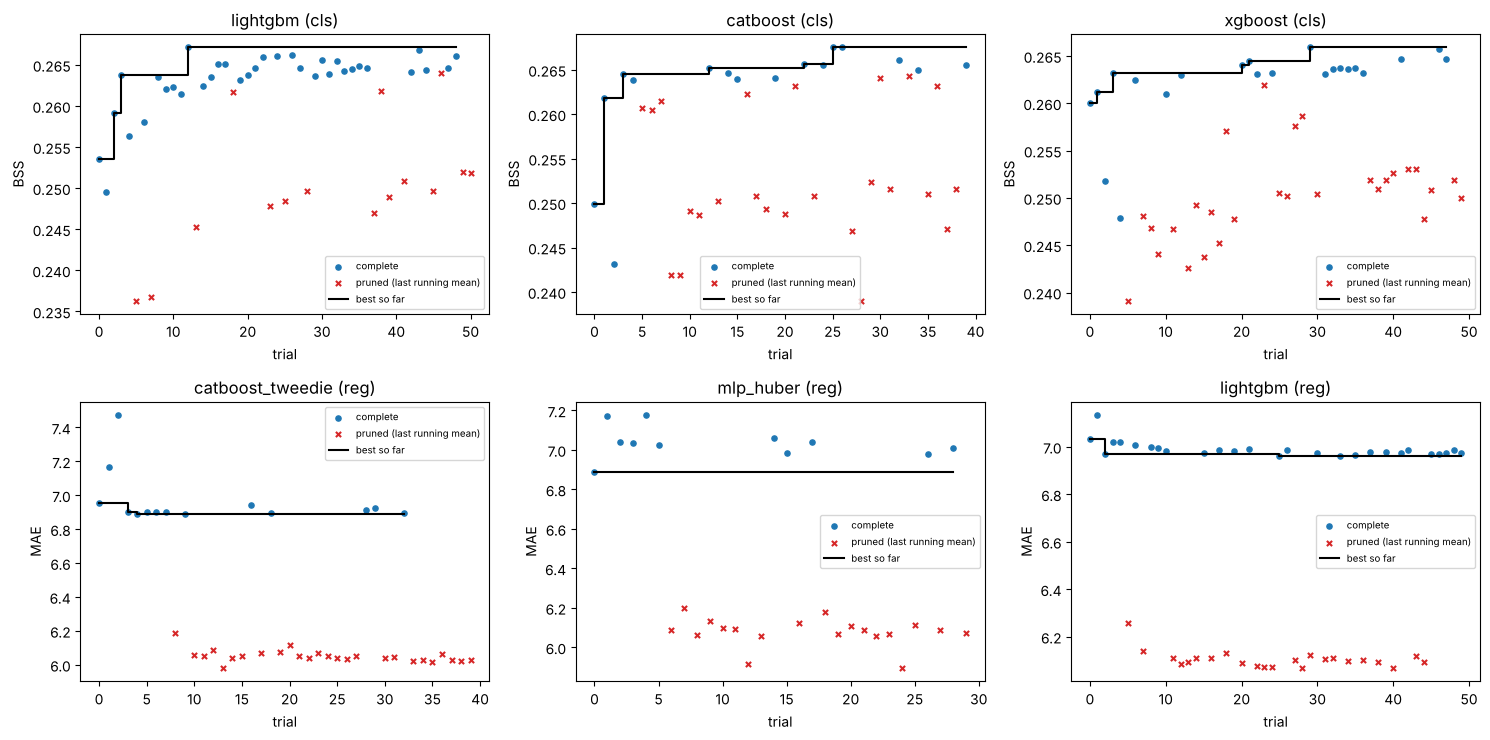

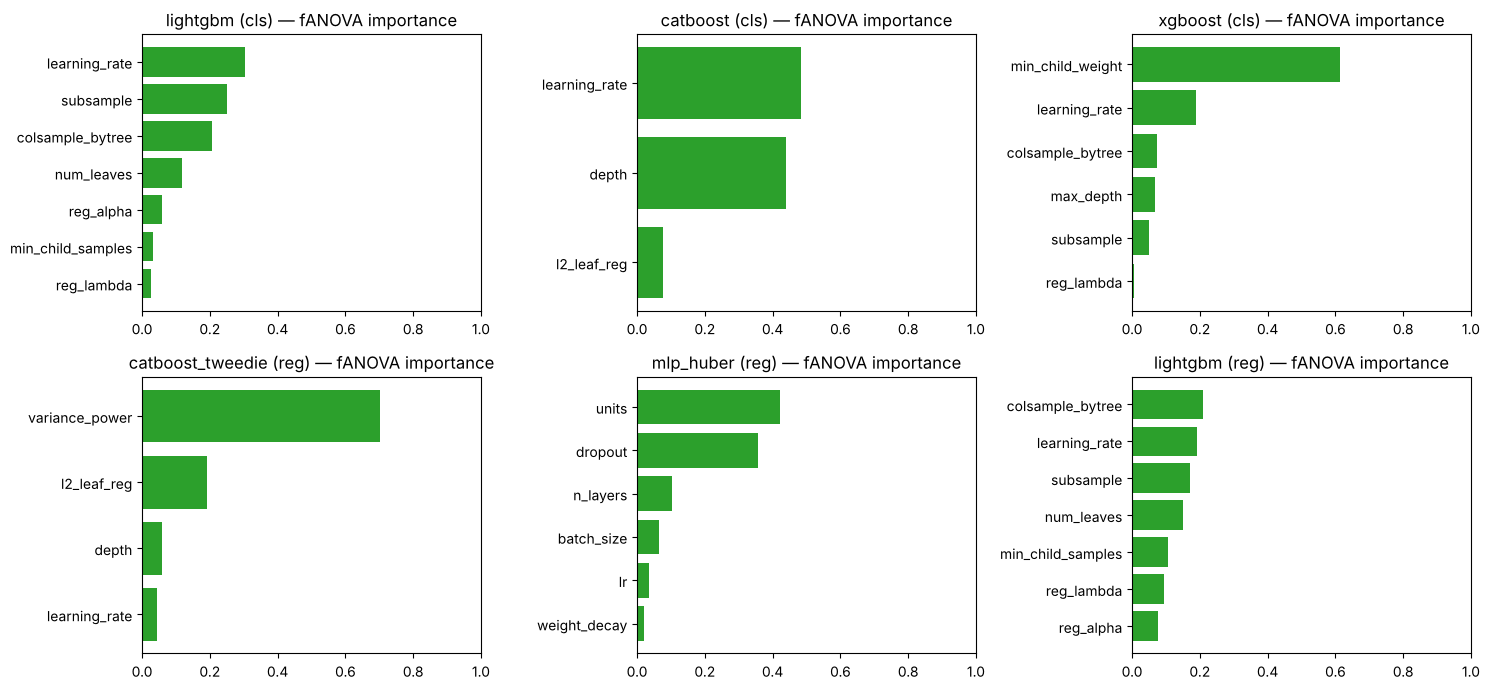

task                   cls                               reg                   
model             catboost lightgbm xgboost catboost_tweedie lightgbm mlp_huber
param                                                                          
batch_size             NaN      NaN     NaN              NaN      NaN     0.065
colsample_bytree       NaN    0.206   0.074              NaN    0.209       NaN
depth                0.440      NaN     NaN            0.060      NaN       NaN
dropout                NaN      NaN     NaN              NaN      NaN     0.358
l2_leaf_reg          0.075      NaN     NaN            0.193      NaN       NaN
learning_rate        0.484    0.303   0.189            0.045    0.193       NaN
lr                     NaN      NaN     NaN              NaN      NaN     0.035
max_depth              NaN      NaN   0.069              NaN      NaN       NaN
min_child_samples      NaN    0.033     NaN              NaN    0.105       NaN
min_child_weight       NaN      NaN   0.612              NaN      NaN       NaN
n_layers               NaN      NaN     NaN              NaN      NaN     0.103
num_leaves             NaN    0.119     NaN              NaN    0.151       NaN
reg_alpha              NaN    0.060     NaN              NaN    0.077       NaN
reg_lambda             NaN    0.028   0.006              NaN    0.096       NaN
subsample              NaN    0.252   0.051              NaN    0.170       NaN
units                  NaN      NaN     NaN              NaN      NaN     0.421
variance_power         NaN      NaN     NaN            0.702      NaN       NaN
weight_decay           NaN      NaN     NaN              NaN      NaN     0.019

In [10]:
def tuned_mean(task, name):
    return per_fold(f"{name}_tuned", task, T.OBJECTIVE[task][0]).mean()
top = {task: sorted([n for t, n in T.BUDGET if t == task], key=lambda n: tuned_mean(task, n),
                    reverse=(task == "cls"))[:3] for task in ("cls", "reg")}
print(top)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
imp_rows = []
for r_, task in enumerate(("cls", "reg")):
    maximize = task == "cls"
    for c_, name in enumerate(top[task]):
        st, ax = studies[task, name], axes[r_, c_]
        done = [t for t in st.trials if t.state.name == "COMPLETE"]
        pruned = [t for t in st.trials if t.state.name == "PRUNED" and t.intermediate_values]
        ax.scatter([t.number for t in done], [t.value for t in done], s=14, label="complete")
        ax.scatter([t.number for t in pruned], [list(t.intermediate_values.values())[-1] for t in pruned], s=14,
                   marker="x", color="tab:red", label="pruned (last running mean)")
        vals = pd.Series({t.number: t.value for t in done}).sort_index()
        ax.step(vals.index, vals.cummax() if maximize else vals.cummin(), where="post", color="k", label="best so far")
        ax.set(title=f"{name} ({task})", xlabel="trial", ylabel=T.OBJECTIVE[task][0])
        ax.legend(fontsize=7)
        imp = optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42))
        imp_rows += [{"task": task, "model": name, "param": p, "importance": v} for p, v in imp.items()]
fig.tight_layout(); save(fig, "06_optuna_history_top3.png"); plt.show()

imp = pd.DataFrame(imp_rows)
imp.to_csv(TAB / "06_param_importance_top3.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for r_, task in enumerate(("cls", "reg")):
    for c_, name in enumerate(top[task]):
        s = imp[(imp.task == task) & (imp.model == name)].sort_values("importance")
        axes[r_, c_].barh(s.param, s.importance, color="tab:green")
        axes[r_, c_].set(title=f"{name} ({task}) — fANOVA importance", xlim=(0, 1))
fig.tight_layout(); save(fig, "06_param_importance_top3.png"); plt.show()
imp.pivot_table(index="param", columns=["task", "model"], values="importance").round(3)

**Interpretation:**
- **Optimisation history:** for the three classification boosters, the best-so-far line rises during the first ≈ 12–30 trials and is flat
  afterwards (LightGBM: last improvement at trial 12 of 50; CatBoost: trial 25 of 40; XGBoost: trial 29 of 50). The budget was sufficient;
  more trials would mostly re-sample noise. For regression the picture is starker: the best MLP is **trial 0** and the best Tweedie trial 4,
  both random start-up trials. Many later trials are within ≈ 0.02 mm. The MAE landscape is flat relative to seed noise, so TPE has
  nothing to exploit. (Red crosses show the running mean at the pruning point; for regression they look "better" only because the early
  folds have lower MAE — they are not comparable with completed trials.)
- **fANOVA importance:** CatBoost-cls: learning rate 0.48 and depth 0.44. LightGBM-cls: learning rate 0.30, then the row/column subsampling fractions
  (0.25, 0.21). XGBoost-cls: `min_child_weight` 0.61. CatBoost Tweedie: **variance power 0.70**, so the distributional assumption matters more than the
  tree settings. MLP regression: width 0.42 and dropout 0.36. These are importances *within the searched ranges* and are estimated from only
  11–35 completed trials (pruned trials are excluded), so the ranking is indicative only.

**Decision:** no extra trials for Part 1. For the deep models (6.3), use a smaller search space (e.g. learning rate, dropout and width only),
because the MLP results show that a flat, noisy landscape wastes trials.

**Paper note:** *The optimisation histories plateaued well within the allotted budgets; learning rate and tree complexity dominated the
hyper-parameter importance of the boosted classifiers, and the Tweedie variance power that of the Tweedie regressor.*

### Step 12 — Red-flag checks after tuning (rule 11)

**WHAT:** (a) the approved plausibility triggers (BSS > 0.45, monsoon ROC-AUC > 0.90, MSESS > 0.60 in any fold) on every tuned
configuration; (b) the test-set audit (latest target date in every OOF file, and which files unlock the test getter).

**WHY:** tuning searches for high scores, so it is exactly where a leak would be amplified.

**Look for:** zero hits; latest target 2019-12-31; only `tests/test_splits.py` unlocks the getter.

In [11]:
t = cv[cv.model.str.endswith("_tuned")]
hits = pd.concat([t[(t.metric == "BSS") & (t.value > 0.45)], t[(t.metric == "ROC_AUC_monsoon") & (t.value > 0.90)],
                  t[(t.metric == "MSESS") & (t.value > 0.60)]])
print("tuned configurations checked:", t.groupby(["model", "task", "seed"]).ngroups, "| rule-11 hits:", len(hits))
print("max fold BSS: %.3f | max monsoon ROC-AUC: %.3f | max fold MSESS: %.3f" % (
    t[t.metric == "BSS"].value.max(), t[t.metric == "ROC_AUC_monsoon"].value.max(), t[t.metric == "MSESS"].value.max()))
Rep.test_set_audit()

tuned configurations checked: 84 | rule-11 hits: 0
max fold BSS: 0.332 | max monsoon ROC-AUC: 0.863 | max fold MSESS: 0.443


{'OOF files checked': 420,
 'latest target date in any OOF file': '2019-12-31',
 'folds present in cv_results': [1, 2, 3, 4, 5],
 'files calling test_index(..., confirm_final=True)': ['tests/test_splits.py']}

**Interpretation:** 84 tuned configuration × seed runs were checked, with **0 rule-11 hits**. The maxima are fold BSS 0.332, monsoon ROC-AUC 0.863 and
fold MSESS 0.443, all below the thresholds and close to the Stage-4 maxima, so tuning did not produce a suspicious jump. All 420 OOF files end
at target 2019-12-31. Only `tests/test_splits.py` (which tests the lock) calls the test getter.

**Decision:** no red flags. Part-1 results can be reported.

**Paper note:** *No tuned configuration exceeded the pre-registered plausibility thresholds, and no forecast for the 2020–2025 test period
was generated during tuning.*

### Stage 6 part 1 — summary

1. **Framework (6.1):** `src/tuning.py`: seeded TPE (seed 42) + median pruning on the running fold mean, the identical Stage-4 fold protocol
   (shared `experiment.fit_fold`), one SQLite study per model in `models/optuna/`, objectives BSS (max) / MAE (min) with PR-AUC, ROC-AUC, Brier,
   CSI, MSESS, RMSE, bias and wet-day MAE in `user_attrs`, and best parameters in `models/optuna/best_params_*.json`. 11 tests prove that there is no
   test-year access and no validation-label leakage.
2. **Tuning (6.2):** 20 studies, 15–100 trials each, ≈ 12 CPU-hours (≈ 5 h wall-clock). The best settings are strongly regularised (C ≈ 0.012, learning
   rate ≈ 0.01–0.02, shallow trees, big RF leaves). Several optima lie at the edge of the playbook ranges.
3. **Default vs tuned:** boosters gain +0.004–0.006 BSS (5/5 folds) and SGD +0.064 (convergence repaired). Regression MAE gains of 0.03–0.11 mm come with a
   more negative bias for the linear models, RF and MLP. Up to half of the stochastic models' apparent gain is seed-0 selection (seeds 1–4 check).
4. **Ranking:** unchanged at the top — tuned LightGBM/CatBoost (BSS 0.265); CatBoost Tweedie (MAE 6.90, 5/5 vs reference); hurdle CatBoost for MSESS
   (0.278).
5. **Integrity:** tuner = runner (identical seed-0 scores), 0 rule-11 hits, no test-period forecasts. Two compute fixes during the run were
   disclosed (RF budget 15, Lasso/EN Gram matrix).

**For your decision before Part 2:** (a) extend the flagged ranges (Ridge α, CatBoost depth, XGBoost depth, LightGBM `reg_lambda`) and re-tune
those studies? (b) tune the hurdle on MSESS instead of MAE, since its role is the mean-type forecast? (c) for 6.3, average 2 seeds per trial
for the deep models?

Outputs: `src/tuning.py`, `tests/test_tuning.py`, `models/optuna/*.db`, `models/optuna/best_params_*.json`, `models/optuna/cv_parts/`,
`models/oof/*_tuned__*`; tables `06_tuning_budget.csv`, `06_best_params.csv`, `06_default_vs_tuned.csv`, `06_master_classification.csv`,
`06_master_regression.csv`, `06_param_importance_top3.csv`, updated `cv_results.csv`; figures `06_pruning_intermediate_values.png`,
`06_default_vs_tuned_paired.png`, `06_optuna_history_top3.png`, `06_param_importance_top3.png`.

### Check your understanding (3 questions)
1. Tuning Lasso, ElasticNet, RF and the MLP for MAE made their bias *more negative* and lowered MSESS, while the tuned Tweedie CatBoost became
   *less* biased. Why does an MAE objective push a model towards under-forecasting on this target, and why might Tweedie behave differently?
2. For tuned CatBoost-classification, the seed-0 optimism (0.0034 BSS) is about as large as the tuning gain (0.0036). Explain where this optimism
   comes from, why the "seeds 1–4" comparison removes part of it, and which part of the optimism remains.
3. The best Ridge α (≈ 99) lies at the upper edge of the search range. What does that tell you, and why must any decision to extend the range
   be made *before* the final evaluation rather than after looking at the test scores?